# BT4012 Competition — Exploratory Data Analysis

Elliptic-style Bitcoin transaction graph. Task: classify transactions as licit (0) or illicit (1).

## Summary of findings

**Scale & structure**
- 141,772 train rows / 15,329 test rows, 165 anonymized, pre-standardized features, plus a temporal `time_step` (train = steps 1–35, test = steps 36–49 — a forward-in-time split).
- Every train `txId` appears in the edge list; degree is right-skewed (median 2, max 473), so a small number of hub transactions dominate connectivity.
- The competition's data dictionary describes the 165 features as a mix of "local" (per-transaction) and "aggregated" (neighbor-statistic) features, but does not disclose which columns are which — there is no confirmed way to split `feat_1`..`feat_165` into the two groups from this data alone, so that boundary is not assumed anywhere below.

**Labels are the only missing values, and most of them are missing**
- 110,537 / 141,772 train rows (78%) have `label = NaN` ("unknown"); only 31,235 (22%) are labeled.
- Among labeled rows, illicit is a minority: 3,644 (11.67%) vs. 27,591 (88.33%) licit — labeled data is already imbalanced, and class composition also shifts across `time_step`.
- No feature column has any missing values — `label` is the sole source of NaNs.

**Feature redundancy is severe**
- 103 feature pairs have |r| > 0.95 across the full 165-feature set, several at exactly r = 1.0 (e.g. `feat_24`/`feat_30`, `feat_59`/`feat_65`) — true duplicates, not just correlated signals.
- Only 5/165 features look roughly normal by skew/kurtosis; several are extremely heavy-tailed (e.g. `feat_34`, `feat_36`, `feat_37` with skew > 200), which matters for any method (VIF, clustering, propagation) that assumes linear relationships or is sensitive to outliers.

## Discussion: my two proposals

**1. Recovering signal from unlabeled rows instead of dropping them.** Dropping the 78% unknown rows throws away most of the dataset, so I want to try an unsupervised technique to see whether these transactions fit into illicit or non-illicit before treating them as unusable, rather than just dropping the NaNs. Caveat to keep in mind: "unknown" doesn't mean "randomly withheld label" — I should treat any recovered label as a weak/soft signal rather than ground truth, validate it against the held-out labeled set before trusting it, and watch for it amplifying the existing 11.67% illicit imbalance or the time-step drift in class composition seen above.

**2. VIF to cut correlated features.** Since the features are aggregates of local features, I expect many of them to be highly correlated, so I want to use VIF to remove some. With 103 pairs at |r| > 0.95 (some exactly 1.0), naive VIF will hit singular/near-singular matrices and blow up to infinity on those pairs, so I'll need to dedupe the near-exact pairs first. But before deciding which of two (or more) highly correlated features to drop, I need to check each feature's significance to `label` first — between collinear features, drop the less label-relevant one rather than picking arbitrarily (e.g. by column order), so I don't accidentally throw away the more useful one.


In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
%matplotlib inline
pd.set_option("display.max_columns", 20)

## Load data

In [2]:
train = pd.read_csv("data/raw/train.csv")
test = pd.read_csv("data/raw/test.csv")
edges = pd.read_csv("data/raw/txs_edgelist.csv")

feat_cols = [c for c in train.columns if c.startswith("feat_")]

print("train:", train.shape)
print("test:", test.shape)
print("edges:", edges.shape)
print("num feature columns:", len(feat_cols))

train: (141772, 168)
test: (15329, 168)
edges: (234355, 2)
num feature columns: 165


In [3]:
train.head()

,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


### `train` vs. `edges`: one row per transaction, vs. one row per connection

Every `txId` appears **exactly once** in `train` (one row = one transaction, with its features). But the same `txId` can appear in **many** rows of `edges` (`txs_edgelist.csv`) — once for every other transaction it's connected to. The example below picks one transaction and shows both: a single row in `train`, but several rows in `edges`.

In [4]:
example_tx = 225885692

print("rows in `train` for this txId (should be exactly 1):")
print(train.loc[train["txId"] == example_tx, ["txId", "time_step", "label"]])

print("\nrows in `edges` for this txId (appears once per connection):")
print(edges[(edges["txId1"] == example_tx) | (edges["txId2"] == example_tx)])

rows in `train` for this txId (should be exactly 1):
            txId  time_step  label
27278  225885692          5    0.0

rows in `edges` for this txId (appears once per connection):
           txId1      txId2
32781  225289477  225885692
34987   20159328  225885692
35455  225288078  225885692
35824  225289113  225885692
36245  225288789  225885692
36870  225320038  225885692


## Label distribution

Only a subset of train rows carry a known label; the rest are `unknown` (NaN).

In [5]:
label_counts = train["label"].value_counts(dropna=False)
label_counts

label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

In [6]:
labeled = train.dropna(subset=["label"]).copy()
labeled["label"] = labeled["label"].astype(int)

print(f"Labeled rows: {len(labeled)} ({len(labeled)/len(train):.1%} of train)")
print(f"Illicit (1) share among labeled: {(labeled['label']==1).mean():.2%}")

Labeled rows: 31235 (22.0% of train)
Illicit (1) share among labeled: 11.67%


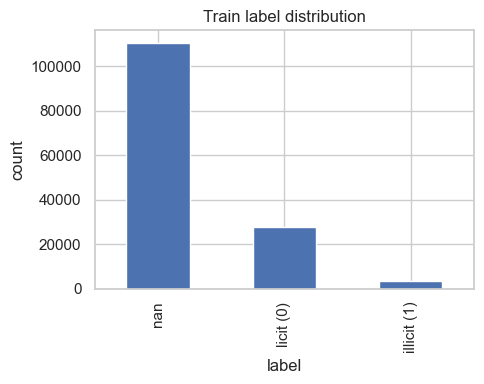

In [7]:
plt.figure(figsize=(5, 4))
label_counts.rename(index={0: "licit (0)", 1: "illicit (1)"}).plot(kind="bar")
plt.title("Train label distribution")
plt.ylabel("count")
plt.tight_layout()
plt.show()

## Missing values

In [8]:
na_counts = train.isna().sum()
na_counts[na_counts > 0]

label    110537
dtype: int64

## time_step distribution

`time_step` gives a temporal split: train covers earlier steps, test covers later ones.

In [9]:
print("train time_steps:", sorted(train["time_step"].unique()))
print("test time_steps:", sorted(test["time_step"].unique()))

train time_steps: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35]
test time_steps: [36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49]


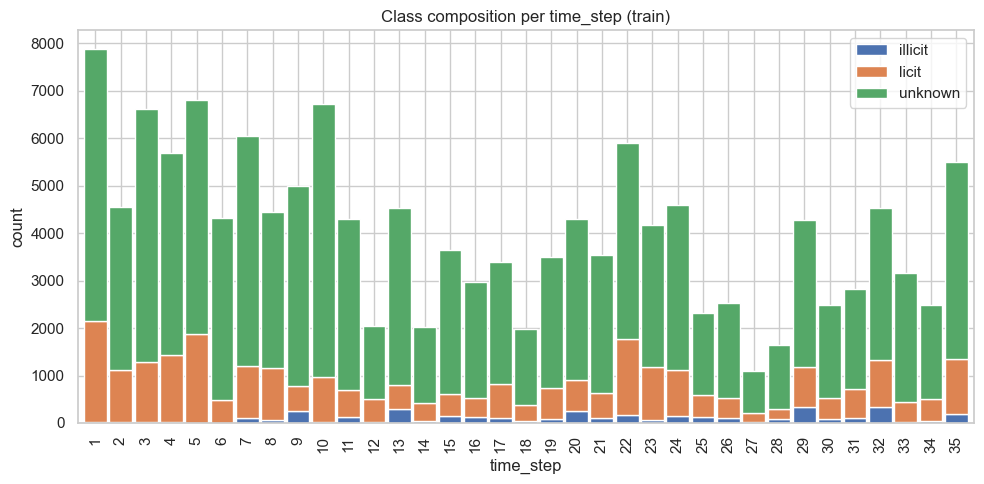

In [10]:
ts_label = (
    train.groupby("time_step")["label"]
    .apply(lambda s: pd.Series({
        "illicit": (s == 1).sum(),
        "licit": (s == 0).sum(),
        "unknown": s.isna().sum(),
    }))
    .unstack()
)

plt.figure(figsize=(10, 5))
ts_label.plot(kind="bar", stacked=True, ax=plt.gca(), width=0.9)
plt.title("Class composition per time_step (train)")
plt.xlabel("time_step")
plt.ylabel("count")
plt.tight_layout()
plt.show()

## Full feature correlation matrix (absolute, 0 to 1)

All 165 features against each other, using |correlation| so strength of relationship (regardless of direction) is easy to compare on one 0-1 scale.

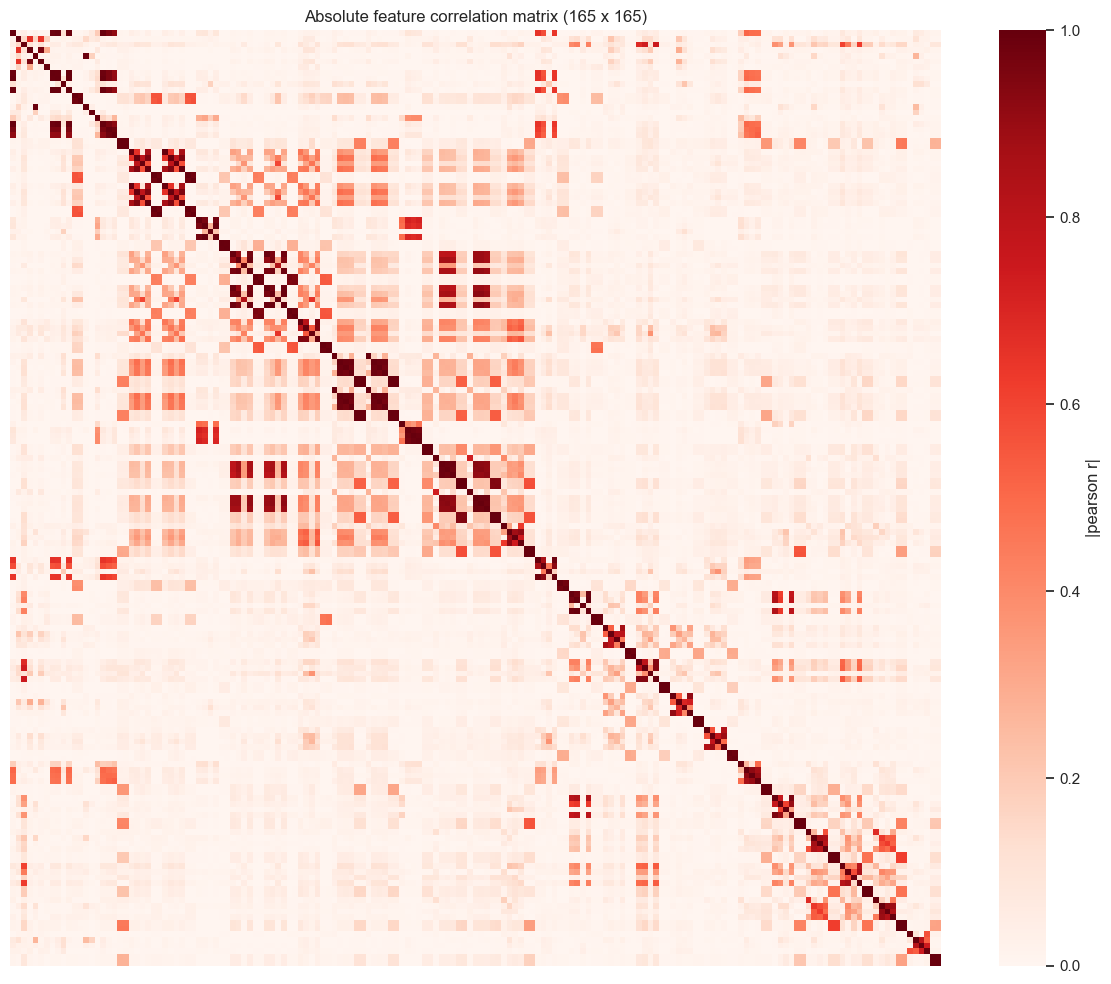

In [11]:
abs_corr_matrix = train[feat_cols].corr().abs()

plt.figure(figsize=(12, 10))
sns.heatmap(abs_corr_matrix, cmap="Reds", vmin=0, vmax=1,
            xticklabels=False, yticklabels=False, cbar_kws={"label": "|pearson r|"})
plt.title("Absolute feature correlation matrix (165 x 165)")
plt.tight_layout()
plt.show()

## Correlation of features with label

In [12]:
corrs = labeled[feat_cols].corrwith(labeled["label"]).abs().sort_values(ascending=False)
corrs.head(15)

feat_53     0.307551
feat_89     0.266436
feat_55     0.261658
feat_90     0.256831
feat_91     0.223915
feat_148    0.196755
feat_150    0.186980
feat_52     0.186078
feat_142    0.180250
feat_54     0.179958
feat_103    0.169814
feat_114    0.169317
feat_112    0.169016
feat_101    0.167378
feat_100    0.165227
dtype: float64

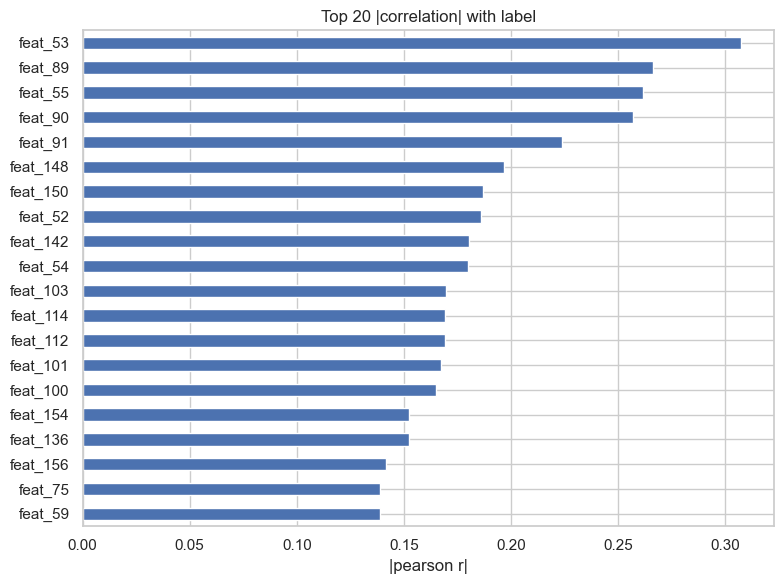

In [13]:
plt.figure(figsize=(8, 6))
corrs.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 |correlation| with label")
plt.xlabel("|pearson r|")
plt.tight_layout()
plt.show()

## Graph structure (edge list)

In [14]:
all_tx_in_edges = pd.concat([edges["txId1"], edges["txId2"]])
degree = all_tx_in_edges.value_counts()

print("unique tx nodes touched by edges:", degree.shape[0])
degree.describe()

unique tx nodes touched by edges: 203769


count    203769.000000
mean          2.300203
std           4.328377
min           1.000000
25%           1.000000
50%           2.000000
75%           2.000000
max         473.000000
Name: count, dtype: float64

In [15]:
print("txIds in train not appearing in edges:", (~train["txId"].isin(all_tx_in_edges)).sum())

txIds in train not appearing in edges: 0


## Normality check

The features are pre-normalized (z-scored: mean≈0, std≈1) but that does **not** mean normally distributed. Skewness and (excess) kurtosis measure how far each feature is from a true normal curve (0 and 0 respectively).

In [16]:
skew = train[feat_cols].skew()
kurt = train[feat_cols].kurtosis()
normality = pd.DataFrame({"skew": skew, "kurtosis": kurt})
normality["abs_skew"] = normality["skew"].abs()
normality["abs_kurt"] = normality["kurtosis"].abs()

near_normal = normality[(normality["abs_skew"] < 0.5) & (normality["abs_kurt"] < 1)]
print(f"roughly-normal features: {len(near_normal)} / {len(feat_cols)}")
normality.sort_values("abs_skew", ascending=False).head(10)

roughly-normal features: 5 / 165


,skew,kurtosis,abs_skew,abs_kurt
feat_34,241.507494,62076.147837,241.507494,62076.147837
feat_36,230.982966,66090.124527,230.982966,66090.124527
feat_37,226.713202,55965.487158,226.713202,55965.487158
feat_35,220.207320,53341.231611,220.207320,53341.231611
feat_73,158.242598,28069.650983,158.242598,28069.650983
feat_72,153.672357,26535.469919,153.672357,26535.469919
feat_71,140.100498,23374.885390,140.100498,23374.885390
feat_14,126.387082,24688.917521,126.387082,24688.917521
feat_162,122.823848,23356.140322,122.823848,23356.140322
feat_5,121.239663,23235.205495,121.239663,23235.205495


### Distribution of every feature

Histogram grid for all 165 features.

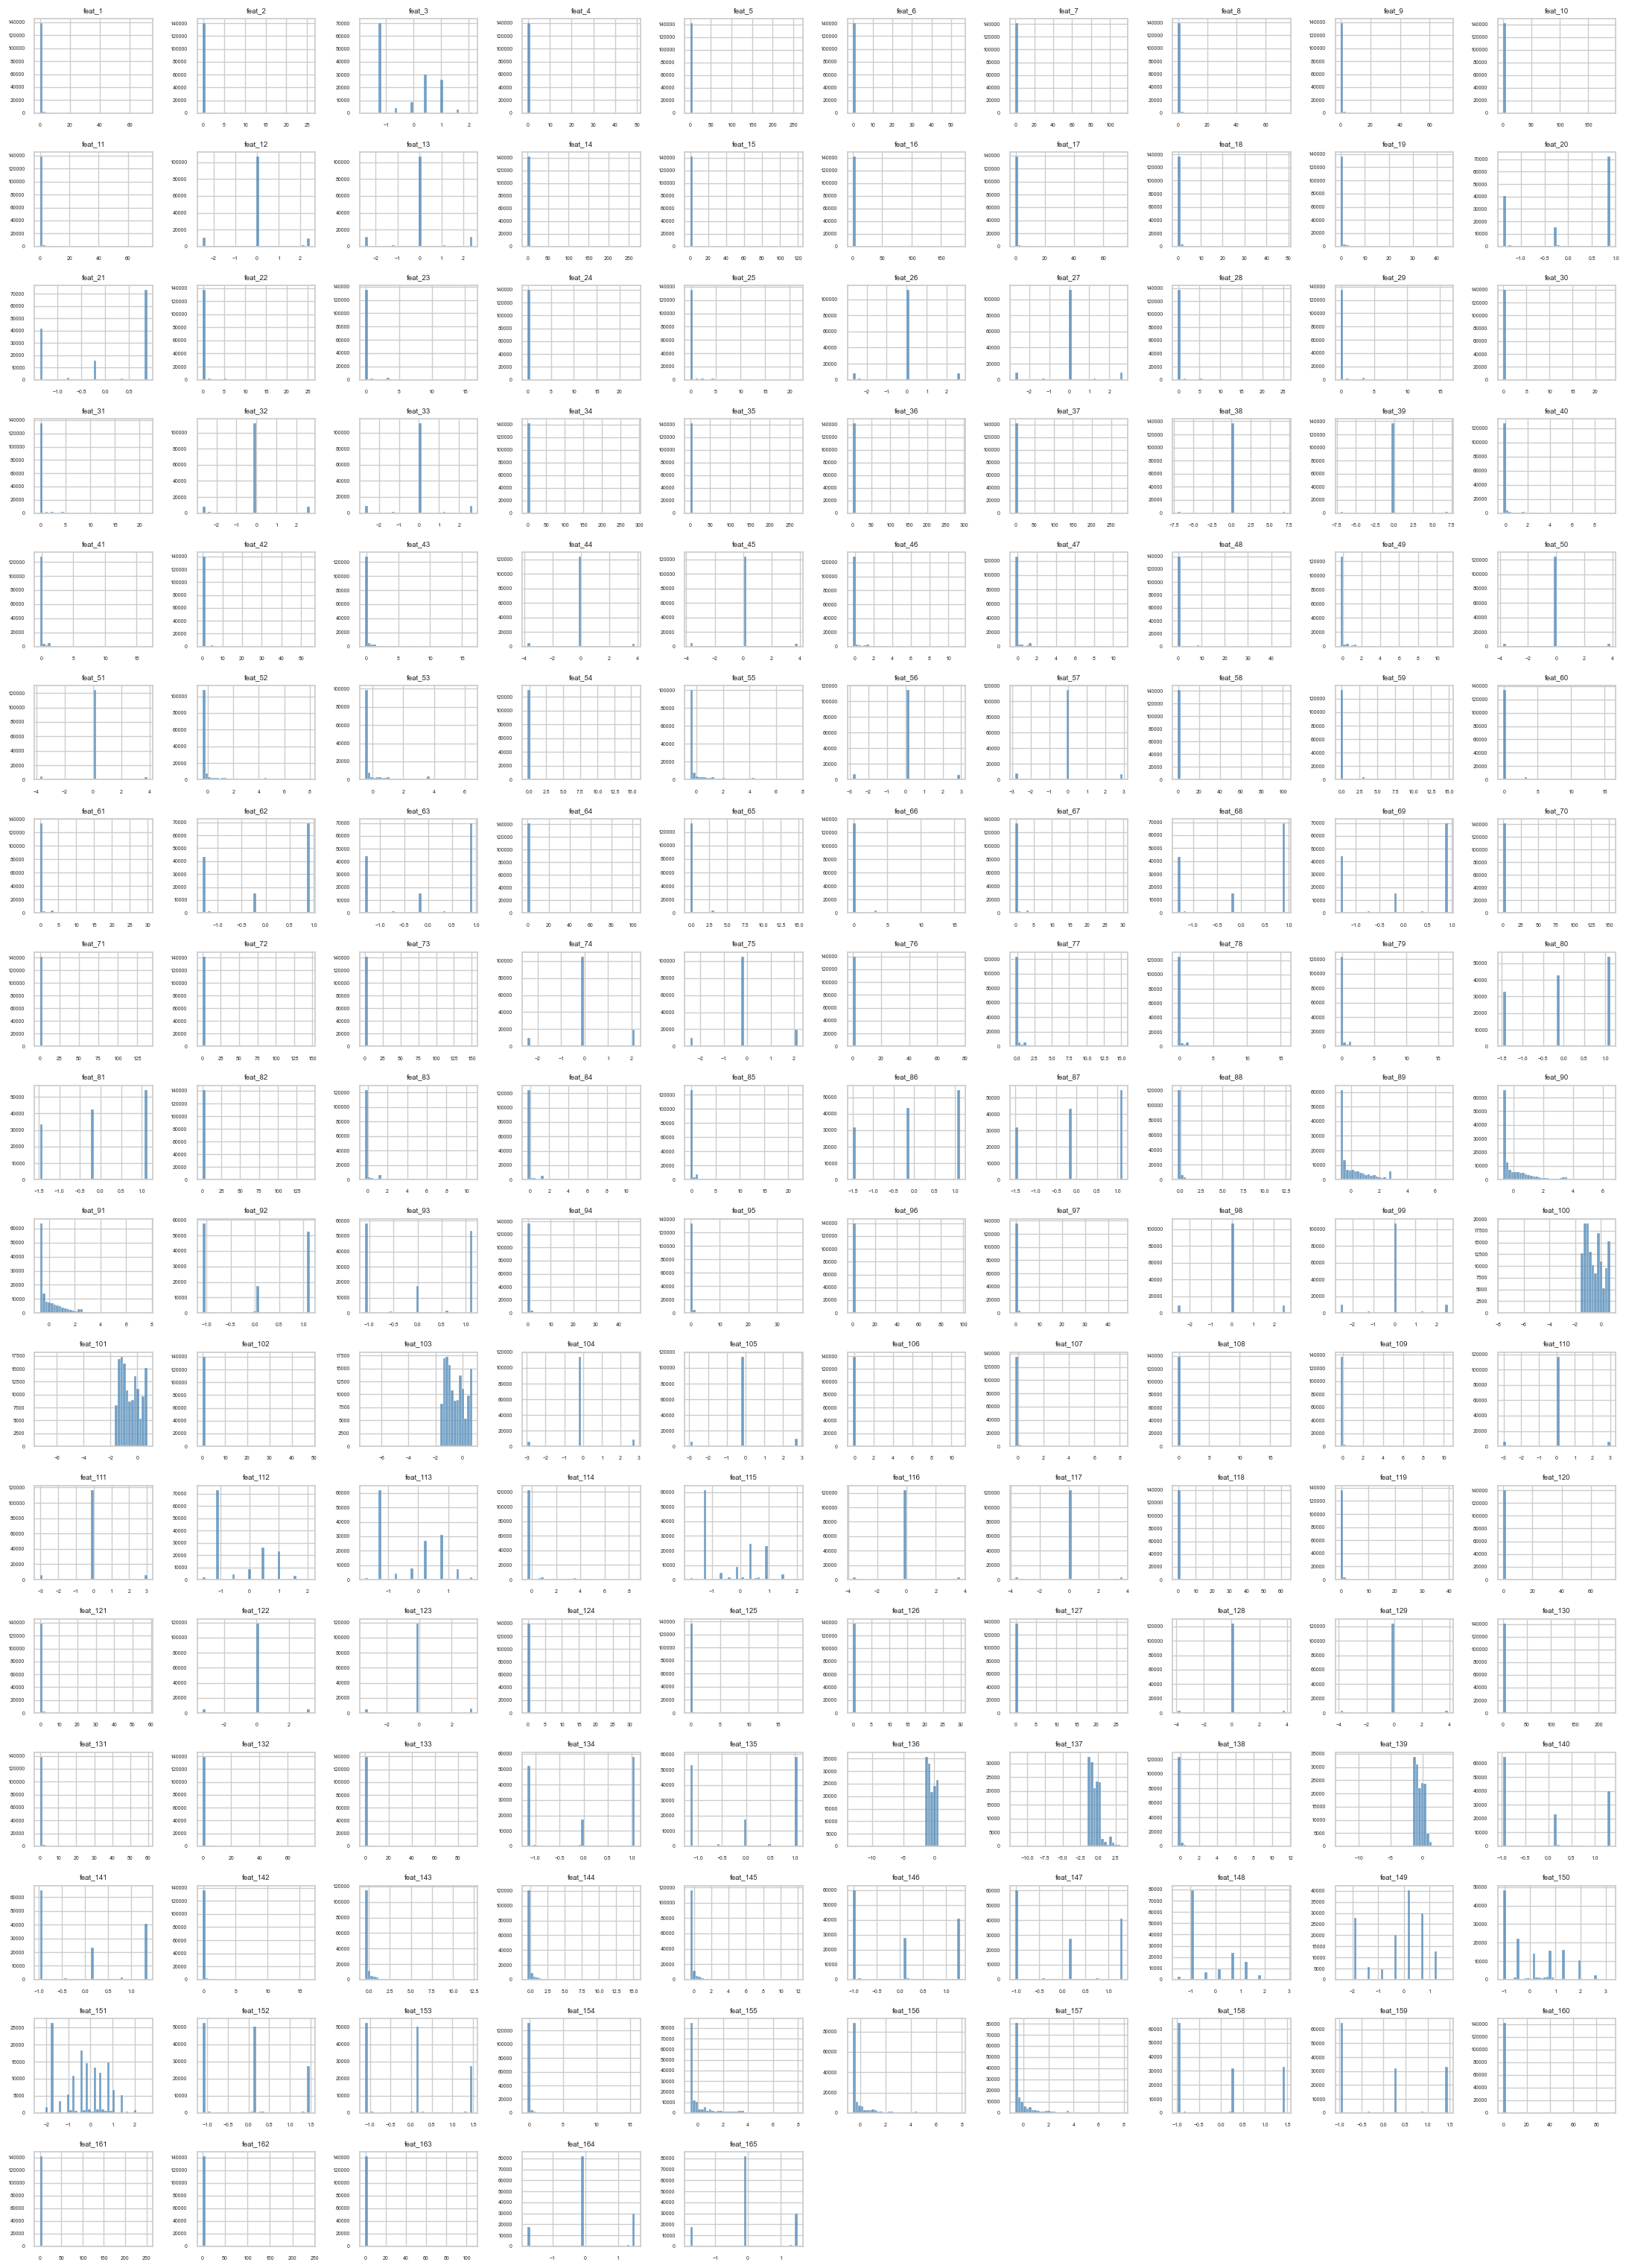

In [17]:
ncols = 10
nrows = math.ceil(len(feat_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.2, nrows * 1.8))
axes = axes.flatten()

for i, col in enumerate(feat_cols):
    ax = axes[i]
    sns.histplot(train[col].dropna(), bins=40, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=7)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(labelsize=5)

for j in range(len(feat_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()